In [13]:
# Imports
import pandas as pd
import seaborn as sns
import pickle 

from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

climate_data = pd.read_csv('data/test_data_with_random_settings_xl.csv')


In [14]:
# Get idea about dataset
climate_data.shape


(1107, 11)

In [15]:
# Get idea about dataset
climate_data.describe()

,t_inside,h_inside,t_outside,h_outside,prev_t_inside,prev_h_inside,prev_t_outside,prev_h_outside,fanTargetSpeed
count,1107.000000,1107.000000,1107.000000,1107.000000,1107.000000,1107.000000,1107.000000,1107.000000,1107.000000
mean,19.602800,52.003613,20.073261,48.594580,19.602891,52.006143,20.074435,48.593857,63.093948
std,0.779403,1.480960,0.960800,1.520019,0.779374,1.480951,0.961260,1.520469,21.698914
min,17.100000,46.900002,18.500000,41.099998,17.100000,46.900002,18.500000,41.099998,0.000000
25%,18.900000,51.000000,19.200001,47.799999,18.900000,51.000000,19.200001,47.799999,45.000000
50%,19.600000,51.900002,20.100000,48.700001,19.600000,51.900002,20.100000,48.700001,63.000000
75%,20.200001,52.900002,20.900000,49.400002,20.200001,52.900002,20.900000,49.400002,82.000000
max,21.500000,57.500000,21.900000,53.000000,21.500000,57.500000,21.900000,53.000000,99.000000


In [16]:
# Prepare data (defining x and y)
climate_data['Heating'] = climate_data['Heating'].astype(bool)
inputSet = climate_data.drop(columns=['t_inside', 'h_inside', 'timestamp'])
outputSet = climate_data[['t_inside', 'h_inside']]

In [17]:
# Splitting Data into train- and testdata
input_train, input_test, output_train, output_test = train_test_split(inputSet, outputSet, test_size=0.2)
input_train.shape, output_train.shape, input_test.shape, output_test.shape

((885, 8), (885, 2), (222, 8), (222, 2))

In [18]:
# Create Model
model = linear_model.LinearRegression()
model.fit(input_train, output_train)

LinearRegression()

In [19]:
# Make Predictions
test_predictions = model.predict(input_test)

In [20]:
# Model Performance

model_mse = mean_squared_error(output_test, test_predictions)
model_r2_score = r2_score(output_test, test_predictions)
score = model.score(input_test, output_test)

print("Score: ", score)
print("Coefficients: ", model.coef_)
print("Intercept: ", model.intercept_)
print("Mean squared error (MSE): ", model_mse)
print("Coefficient of determination (R^2): ", model_r2_score)
#print("Mean absolute error (MEA): ", model.mea)

Score:  0.9508677895989834
Coefficients:  [[ 5.98928879e-01 -2.84895767e-02  8.24197514e-01 -2.38951981e-03
  -4.58214599e-01  3.23121053e-02 -1.09183293e-04  2.90828787e-03]
 [-4.69650903e-01  3.68148146e-01 -9.59644141e-01  6.90648774e-01
   1.45116760e+00 -6.69647517e-02  3.51783429e-04 -5.18927436e-03]]
Intercept:  [0.56310981 0.53955069]
Mean squared error (MSE):  0.07084773977033032
Coefficient of determination (R^2):  0.9508677895989834


In [21]:
model.predict([[20.10000038, 49.5, 19.10000038, 54.29999924, 20, 49.59999847, 32, False]])


array([[19.23866289, 54.20908252]])

<AxesSubplot:xlabel='t_inside'>

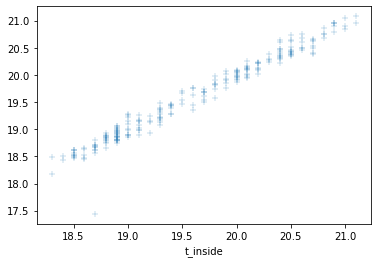

In [22]:
# Create Plots


test_t = output_test["t_inside"]
test_h = output_test["h_inside"]
predicted_t = test_predictions[:,0]
predicted_h = test_predictions[:,1]

# temperature
sns.scatterplot(x = test_t, y = predicted_t, marker="+", alpha=0.5 )

<AxesSubplot:xlabel='h_inside'>

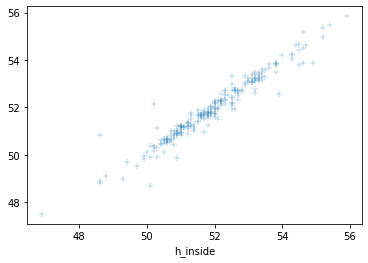

In [23]:
# humidity
sns.scatterplot(x=test_h, y = predicted_h, marker="+", alpha=0.5)

In [24]:
pkl_filename = "model_lin_reg_xl.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(model, file)